In [1]:
import numpy as np
import moments 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import demes 
import demesdraw
import pandas
import pickle
from matplotlib.transforms import ScaledTranslation


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [31]:
h2_nomig = pandas.read_csv("data/params.nomig.all.h2.txt", sep="\t")
sfs_nomig = pandas.read_csv("data/params.nomig.all.sfs.txt", sep="\t")
h2_mig = pandas.read_csv("data/params.mig.all.h2.txt", sep="\t")
sfs_mig = pandas.read_csv("data/params.mig.all.sfs.txt", sep="\t")
graph = demes.load("data/model_mig.yaml")

print(h2_mig)

               Ne          NAMH          NND           NN           ND  \
0    14970.537464  19984.952007  4452.250867  2578.840949  3967.392409   
1    14937.947889  20106.761632  4962.024030  2434.781846  4055.092664   
2    14916.640816  19942.388828  5163.422453  2482.567411  3914.367967   
3    14885.063579  20058.297642  5004.366370  2545.481873  3999.727961   
4    14903.922644  19950.650986  4981.074541  2539.752243  3965.390197   
..            ...           ...          ...          ...          ...   
195  14895.661033  19894.567293  4974.425996  2468.959289  3937.742535   
196  14907.653925  19904.136854  4949.541288  2454.860464  4012.863153   
197  14940.330921  19921.072759  4977.420567  2514.705373  3956.907363   
198  14929.667226  19893.353023  4955.348181  2515.676199  4033.245559   
199  14894.798529  19952.693196  5133.074073  2468.277576  3964.851855   

              TAMH            TND       mND         LL  
0    748477.304896  611197.607651  0.000010 -11.695899

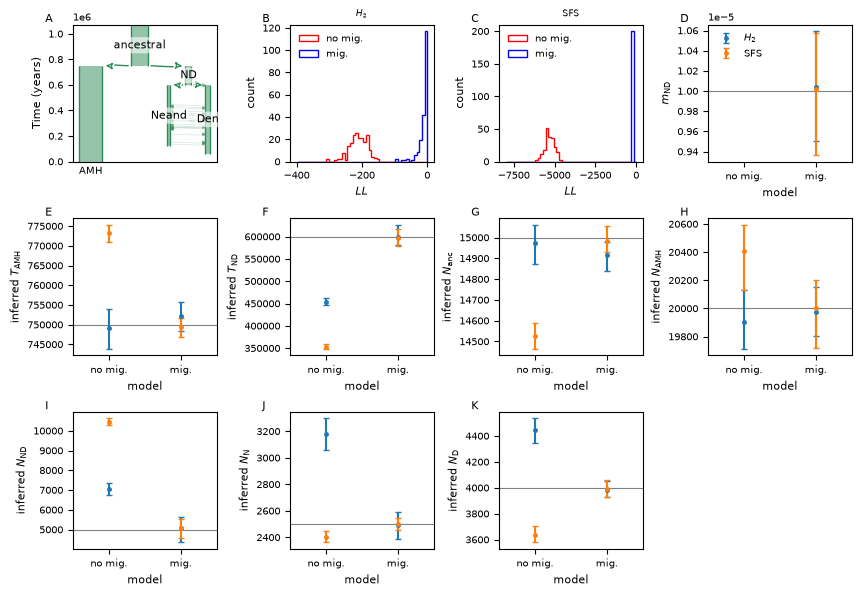

In [48]:
def plot_model(ax):
    demesdraw.tubes(
        graph,
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel("Time (years)")
    return


def plot_ll_distr_h2(ax):
    bins = np.linspace(-400, 0, 50)
    ax.hist(np.array(h2_nomig["LL"]), histtype="step", bins=bins, label="no mig.", color="red")
    ax.hist(np.array(h2_mig["LL"]), histtype="step", bins=bins, label="mig.", color="blue")
    ax.legend(framealpha=0)
    ax.set_title("$H_2$")
    ax.set_xlabel("$LL$")
    ax.set_ylabel("count")
    return


def plot_ll_distr_sfs(ax):
    bins = np.linspace(-8000, 0, 50)
    ax.hist(-np.array(sfs_nomig["LL"]), histtype="step", bins=bins, label="no mig.", color="red")
    ax.hist(-np.array(sfs_mig["LL"]), histtype="step", bins=bins, label="mig.", color="blue")
    ax.legend(framealpha=0)
    ax.set_title("SFS")
    ax.set_xlabel("$LL$")
    ax.set_ylabel("count")
    return


def plot_param_mig(ax, param, label, true_val):
    ys_h2_mig = h2_mig[param]
    ys_sfs_mig = sfs_mig[param]
    arrs = [
        ys_h2_mig,
        ys_sfs_mig,
    ]
    xs = [1, 1]
    colors = ["tab:blue", "tab:orange"]
    labels = ["$H_2$", "SFS"]
    ax.hlines(true_val, -0.5, 1.5, lw=0.8, color="grey")
    for i, arr in enumerate(arrs):
        med = np.median(arr)
        low = med - np.quantile(arr, 0.025)
        high = np.quantile(arr, 0.975) - med
        ax.errorbar([xs[i]], [med], yerr=([low], [high]), color=colors[i],
                    fmt=".", label=labels[i], markersize=5, capsize=2)
    ax.legend(framealpha=0)
    ax.set_ylabel(label)
    ax.set_xlabel("model")
    ax.set_xlim(-0.5, 1.5)
    ax.set_xticks([0, 1], ["no mig.", "mig."])
    return


def plot_param(ax, param, label, true_val):
    ys_h2_nomig = h2_nomig[param]
    ys_sfs_nomig = sfs_nomig[param]
    ys_h2_mig = h2_mig[param]
    ys_sfs_mig = sfs_mig[param]
    arrs = [
        ys_h2_nomig,
        ys_sfs_nomig,
        ys_h2_mig,
        ys_sfs_mig,
    ]
    xs = [0, 0, 1, 1]
    colors = ["tab:blue", "tab:orange", "tab:blue", "tab:orange"]
    labels = ["$H_2$", "SFS", None, None]
    ax.hlines(true_val, -0.5, 1.5, lw=0.8, color="grey")
    for i, arr in enumerate(arrs):
        med = np.median(arr)
        low = med - np.quantile(arr, 0.025)
        high = np.quantile(arr, 0.975) - med
        ax.errorbar([xs[i]], [med], yerr=([low], [high]), color=colors[i],
                    fmt=".", label=labels[i], markersize=5, capsize=2)
    ax.set_ylabel("inferred " + label)
    ax.set_xlabel("model")
    ax.set_xlim(-0.5, 1.5)
    ax.set_xticks([0, 1], ["no mig.", "mig."])
    return


mosaic = "ABCD;EFGH;IJK."
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 5.85), layout="constrained")
for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))
plot_model(axs["A"])
plot_ll_distr_h2(axs["B"])
plot_ll_distr_sfs(axs["C"])
plot_param_mig(axs["D"], "mND", "$m_\\text{ND}$", 1e-5)
axs["D"].legend(framealpha=0)
plot_param(axs["E"], "TAMH", "$T_\\text{AMH}$", 7.5e5)
plot_param(axs["F"], "TND", "$T_\\text{ND}$", 6e5)
plot_param(axs["G"], "Ne", "$N_\\text{anc}$", 1.5e4)
plot_param(axs["H"], "NAMH", "$N_\\text{AMH}$", 2e4)
plot_param(axs["I"], "NND", "$N_\\text{ND}$", 5e3)
plot_param(axs["J"], "NN", "$N_\\text{N}$", 2.5e3)
plot_param(axs["K"], "ND", "$N_\\text{D}$", 4e3)
plt.savefig("../../figures/migration_misspec.pdf")